# Phase 1b — Coupling-degree hypothesis (pre-registered confirmation test)

**Context.** Phase 1 rejected the causal-cone hypothesis (H1). Exploratory analysis of Phase 1 suggested that a qubit's concentration is set by its own **coupling degree** $d_k$ (number of ZZ couplings acting on it) together with the layer count L. Phase 1b tests that idea as a new, frozen hypothesis on **new graphs, larger circuits (up to 14 qubits) and data rows never used before**.

**H2.** The Bloch-vector variance $V_k=\operatorname{tr}\operatorname{Cov}_x[r_k(x)]$ of qubit k is governed by $d_k$ and L, not by its causal-cone size $|C_L(k)|$ and not by global graph density.

**Exact single-layer result (verified in Section 3).** For L = 1, with $t_k=c\,x_k$ and $p_{kj}=c^2x_kx_j$,
$$r_k=\big(\sin t_k\,\mathrm{Re}\,P_k,\ \sin t_k\,\mathrm{Im}\,P_k,\ \cos t_k\big),\qquad P_k=\prod_{j\in N(k)}\big(\cos p_{kj}+i\sin p_{kj}\cos t_j\big),$$
so each coupling multiplies the qubit's transverse signal by a factor of modulus $\sqrt{1-\sin^2p_{kj}\sin^2t_j}\le 1$. The formula has the same structure as known single-layer QAOA expectation values; what Phase 1b tests is whether the *degree* picture still holds for L = 2, 3, where no closed form is used.

| Section | Content | Checkpoint |
|---|---|---|
| 1 | Configuration; verification of both freezes and of this notebook's code hash | All verified |
| 2 | Fresh inputs (rows not used in Phase 1) | Overlap with Phase 1 rows = 0 |
| 3 | Simulator (unchanged from Phase 1) + checks + closed-form check C5 | Four PASS lines |
| 4 | Graph families with per-qubit degree and cone size | Graph table |
| 5 | Experiment: per-qubit $V_k$ for every configuration | Results CSV |
| 6 | Criteria C1–C4, verdict, figures | Verdict printed |

Run `MODE = "smoke"` first (seconds), then `MODE = "run"`. Do not edit any code except the MODE line: the freeze records a hash of the code.

## 1. Configuration and freeze verification

In [8]:
from pathlib import Path
import os, json, hashlib, time, itertools, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=FutureWarning)

MODE = "run"             # "smoke" -> Gaussian inputs, small grid | "run" -> the frozen Phase 1b test
ROOT = Path(os.environ.get("PQK_ROOT", Path.cwd() / "pqk-nids"))
NOTEBOOK = Path(os.environ.get("PQK_P1B_NOTEBOOK", Path.cwd() / "phase1b_degree_test.ipynb"))
PHASE0_MODE = "quick"; GLOBAL_SEED = 20261001
RES = ROOT / "results" / "phase1b" / MODE; RES.mkdir(parents=True, exist_ok=True)

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

def code_hash(path):
    nb = json.loads(Path(path).read_text())
    src = []
    for c in nb["cells"]:
        if c["cell_type"] == "code":
            s = "".join(c["source"]) if isinstance(c["source"], list) else c["source"]
            src.append("\n".join(l for l in s.splitlines() if not l.strip().startswith("MODE =")))
    return hashlib.sha256("\n#----\n".join(src).encode()).hexdigest()

if MODE == "run":
    F1 = ROOT / "phase1_freeze" / "phase1_frozen_inputs.json"; F1b = ROOT / "phase1b_freeze" / "phase1b_frozen.json"
    assert F1b.exists(), "No Phase 1b freeze. Run freeze_phase1b.py first."
    t1b = F1b.read_text(); assert hashlib.sha256(t1b.encode()).hexdigest() == (F1b.parent / "phase1b_frozen.json.sha256").read_text().split()[0], "Phase 1b freeze modified"
    FZB = json.loads(t1b)
    t1 = F1.read_text(); assert hashlib.sha256(t1.encode()).hexdigest() == FZB["builds_on"]["phase1_freeze_sha256"], "Phase 1 freeze differs from the one Phase 1b builds on"
    FZ1 = json.loads(t1)
    bad = [k for k, v in FZ1["file_sha256"].items() if sha(ROOT / k) != v]
    assert not bad, f"Inputs changed since the Phase 1 freeze: {bad}"
    assert NOTEBOOK.exists(), f"Save this notebook as {NOTEBOOK} (or set PQK_P1B_NOTEBOOK) so its code can be verified"
    assert code_hash(NOTEBOOK) == FZB["notebook_code_sha256"], "This notebook's code differs from the frozen code (only the MODE line may change). Save the notebook and re-check."
    G = FZB["grid"]; QUBITS, LAYERS, BANDWIDTHS, NSAMP = G["qubits"], G["layers"], G["bandwidths"], G["samples_per_config"]
    print(f"Phase 1b freeze verified (created {FZB['created']}); Phase 1 inputs unchanged; notebook code matches the frozen hash.")
else:
    FZ1 = FZB = None
    QUBITS, LAYERS, BANDWIDTHS, NSAMP = [8, 10], [1, 2], [0.6], 40
print(f"MODE={MODE}  qubits={QUBITS}  layers={LAYERS}  bandwidths={BANDWIDTHS}  samples/config={NSAMP}")
print("CHECKPOINT 1: configuration ready.")

Phase 1b freeze verified (created 2026-10-06 19:12:25 EDT); Phase 1 inputs unchanged; notebook code matches the frozen hash.
MODE=run  qubits=[8, 10, 12, 14]  layers=[1, 2, 3]  bandwidths=[0.3, 0.6, 1.0]  samples/config=200
CHECKPOINT 1: configuration ready.


## 2. Fresh inputs

Each dataset contributes 200 training rows drawn with seed 20261001+1 **after removing every row used in Phase 1**, so Phase 1b is evaluated on data it was not designed from. The Gaussian control uses a new seed as well.

In [9]:
import joblib
def signed_log1p(X):   # needed to unpickle the Phase 0 preprocessors
    return np.sign(X) * np.log1p(np.abs(X))

NMAX = max(QUBITS)
INPUTS = {"gaussian": np.random.default_rng(GLOBAL_SEED + 1).standard_normal((NSAMP, NMAX))}
OVERLAP = {}
if MODE == "run":
    PROC = ROOT / "data" / "processed"; ranks = json.load(open(ROOT / "results" / "phase0" / PHASE0_MODE / "feature_rankings.json"))
    def fresh_rows(ds):
        tr = pd.read_parquet(PROC / ds / f"train_{PHASE0_MODE}.parquet")
        used = np.sort(np.random.default_rng(GLOBAL_SEED).choice(len(tr), 200, replace=False))      # Phase 1 rows
        pool = np.setdiff1d(np.arange(len(tr)), used)
        idx = np.sort(np.random.default_rng(GLOBAL_SEED + 1).choice(pool, NSAMP, replace=False))
        OVERLAP[ds] = int(np.intersect1d(idx, used).size)
        return tr.iloc[idx]
    tr = fresh_rows("fashion_mnist"); pre = joblib.load(PROC / "fashion_mnist" / f"preprocessor_{PHASE0_MODE}.joblib")
    pca, sc = joblib.load(PROC / "fashion_mnist" / f"pca_{PHASE0_MODE}.joblib")[16]
    INPUTS["fashion_mnist"] = sc.transform(pca.transform(pre["ct"].transform(tr[pre["cols"]])))[:, :NMAX]
    for ds in ["nf_unsw_nb15_v2", "unsw_nb15"]:
        tr = fresh_rows(ds); pre = joblib.load(PROC / ds / f"preprocessor_{PHASE0_MODE}.joblib")
        X = pre["ct"].transform(tr[pre["cols"]]); names = list(pre["names"])
        assert ranks[ds]["mi"][:16] == FZ1["feature_definitions"][f"{ds}/mi16"], "MI-16 list differs from the Phase 1 freeze"
        INPUTS[ds] = np.asarray(X[:, [names.index(f) for f in ranks[ds]["mi"][:16]]], dtype=float)[:, :NMAX]
    assert all(v == 0 for v in OVERLAP.values()), f"fresh rows overlap Phase 1 rows: {OVERLAP}"
INPUTS = {k: np.asarray(v, dtype=np.float64) for k, v in INPUTS.items()}   # scikit-learn can return float32; simulate in float64
for k, v in INPUTS.items():
    print(f"{k:18s} shape={v.shape}  mean={v.mean():+.3f}  sd={v.std():.3f}" + (f"  rows shared with Phase 1: {OVERLAP[k]}" if k in OVERLAP else ""))
print("CHECKPOINT 2: fresh inputs loaded.")

gaussian           shape=(200, 14)  mean=-0.010  sd=1.004
fashion_mnist      shape=(200, 14)  mean=-0.022  sd=0.998  rows shared with Phase 1: 0
nf_unsw_nb15_v2    shape=(200, 14)  mean=+0.017  sd=0.960  rows shared with Phase 1: 0
unsw_nb15          shape=(200, 14)  mean=-0.006  sd=0.985  rows shared with Phase 1: 0
CHECKPOINT 2: fresh inputs loaded.


## 3. Simulator (identical to Phase 1) and verification

The simulator code is copied unchanged from the Phase 1 notebook. Checks: dense-unitary agreement, normalisation, and **C5**, the exact single-layer formula above, on every graph family at n = 8 and n = 10 for all inputs.

In [10]:
def zsigns(n):
    D = 2 ** n
    bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))) & 1   # qubit 0 = most significant bit
    return 1 - 2 * bits                                            # (D, n), Z eigenvalues +1/-1

def simulate(X, edges, L, c):
    # X: (N, n) features. Returns (N, 2**n) states U(x)|0...0>.
    N, n = X.shape; D = 2 ** n
    psi = np.zeros((N, D), dtype=complex); psi[:, 0] = 1.0
    if edges:
        s = zsigns(n); S = np.stack([s[:, i] * s[:, j] for i, j in edges], 1)          # (D, E)
        W = np.stack([X[:, i] * X[:, j] for i, j in edges], 1)                         # (N, E)
        phase = np.exp(-0.5j * (c ** 2) * (W @ S.T))                                    # (N, D)
    for _ in range(L):
        for k in range(n):
            th = c * X[:, k]; co = np.cos(th / 2)[:, None, None]; si = np.sin(th / 2)[:, None, None]
            p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1))
            a0 = p[:, :, 0, :].copy(); a1 = p[:, :, 1, :].copy()
            p[:, :, 0, :] = co * a0 - si * a1
            p[:, :, 1, :] = si * a0 + co * a1
        if edges:
            psi = psi * phase
    return psi

def bloch(psi, n):
    N = psi.shape[0]; R = np.empty((N, n, 3))
    for k in range(n):
        p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1)); a0, a1 = p[:, :, 0, :], p[:, :, 1, :]
        r01 = (a0 * a1.conj()).sum((1, 2))
        R[:, k] = np.stack([2 * r01.real, -2 * r01.imag, (abs(a0) ** 2).sum((1, 2)) - (abs(a1) ** 2).sum((1, 2))], 1)
    return R

def dense_state(x, edges, L, c):
    n = len(x); I = np.eye(2)
    def on(k, g):
        out = np.array([[1.0]])
        for q in range(n): out = np.kron(out, g if q == k else I)
        return out
    U = np.eye(2 ** n, dtype=complex)
    for _ in range(L):
        for k in range(n):
            t = c * x[k]; U = on(k, np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])) @ U
        for i, j in edges:
            ZZ = on(i, np.diag([1., -1.])) @ on(j, np.diag([1., -1.]))
            U = (np.cos(c ** 2 * x[i] * x[j] / 2) * np.eye(2 ** n) - 1j * np.sin(c ** 2 * x[i] * x[j] / 2) * ZZ) @ U
    v = np.zeros(2 ** n, dtype=complex); v[0] = 1; return U @ v


import networkx as nx

def neighbours(n, edges):
    nb = {k: [] for k in range(n)}
    for i, j in edges: nb[i].append(j); nb[j].append(i)
    return nb

def closed_form_L1(X, edges, c):
    n = X.shape[1]; nb = neighbours(n, edges); R = np.empty((X.shape[0], n, 3))
    for k in range(n):
        t = c * X[:, k]; P = np.ones(X.shape[0], dtype=complex)
        for j in nb[k]:
            p = c ** 2 * X[:, k] * X[:, j]; P = P * (np.cos(p) + 1j * np.sin(p) * np.cos(c * X[:, j]))
        R[:, k] = np.stack([np.sin(t) * P.real, np.sin(t) * P.imag, np.cos(t)], 1)
    return R

CHECKS = {}
t = np.random.default_rng(1).standard_normal((5, 3)); e3 = [(0, 1), (1, 2), (0, 2)]
d = max(np.abs(simulate(t, e3, 2, 0.8)[i] - dense_state(t[i], e3, 2, 0.8)).max() for i in range(5))
CHECKS["dense_check_n3"] = dict(max_abs_diff=float(d), pass_=bool(d < 1e-12))

## 4. Graph families, coupling degree and cone size per qubit

In [11]:
def families(n, seed=GLOBAL_SEED):
    F = {"empty": [], "chain": [(i, i + 1) for i in range(n - 1)], "ring": [(i, (i + 1) % n) for i in range(n)],
         "star": [(0, i) for i in range(1, n)], "complete": [(i, j) for i in range(n) for j in range(i + 1, n)],
         "wheel": [(0, i) for i in range(1, n)] + [(i, i % (n - 1) + 1) for i in range(1, n)]}
    h = n // 2
    F["double_star"] = [(0, 1)] + [(0, i) for i in range(2, h + 1)] + [(1, i) for i in range(h + 1, n)]
    if n % 2 == 0: F["matching"] = [(i, i + 1) for i in range(0, n, 2)]
    def cycles(sizes):
        e, s0 = [], 0
        for m in sizes:
            e += [(s0 + i, s0 + (i + 1) % m) for i in range(m)]; s0 += m
        return e
    if n % 4 == 0: F["cycles4"] = cycles([4] * (n // 4))
    if n % 3 == 0: F["triangles"] = cycles([3] * (n // 3))
    F["two_cycles"] = cycles([n // 2, n - n // 2])
    if n % 4 == 0: F["k4s"] = sum(([(b + i, b + j) for i in range(4) for j in range(i + 1, 4)] for b in range(0, n, 4)), [])
    if n % 2 == 0:
        for s in range(seed, seed + 500):
            g = nx.random_regular_graph(3, n, seed=s)
            if nx.is_connected(g): F["regular3"] = sorted(tuple(sorted(e)) for e in g.edges()); break
    for tag, off in [("a", 0), ("b", 1000)]:
        for s in range(seed + off, seed + off + 500):
            g = nx.gnp_random_graph(n, 0.3, seed=s)
            if nx.is_connected(g): F[f"erdos_renyi_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges()); break
        r = np.random.default_rng(seed + off + n)
        g = nx.from_prufer_sequence(list(r.integers(0, n, n - 2)))
        F[f"random_tree_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges())
    out, seen = {}, set()   # drop duplicate edge sets (e.g. two_cycles == cycles4 at n = 8)
    for k, E in F.items():
        key = frozenset(tuple(sorted(e)) for e in E)
        if key not in seen: seen.add(key); out[k] = [tuple(sorted(e)) for e in E]
    return out

def per_qubit(n, edges, L):
    g = nx.Graph(); g.add_nodes_from(range(n)); g.add_edges_from(edges)
    deg = np.array([g.degree(k) for k in range(n)])
    cone = np.array([len(nx.single_source_shortest_path_length(g, k, cutoff=L)) for k in range(n)])
    return deg, cone

# C5: closed form vs simulator, L = 1, n = 8 and 10, every family, every input set, every bandwidth
c5 = 0.0
for n in [8, 10]:
    for name, E in families(n).items():
        for src, Xall in INPUTS.items():
            for c in BANDWIDTHS:
                X = Xall[:, :n]
                c5 = max(c5, float(np.abs(bloch(simulate(X, E, 1, c), n) - closed_form_L1(X, E, c)).max()))
CHECKS["C5_closed_form_L1"] = dict(max_abs_diff=c5, pass_=bool(c5 < 1e-10))
x = np.random.default_rng(2).standard_normal((3, 8)); ne = max(abs(np.linalg.norm(simulate(x, E, 3, 1.0), axis=1) - 1).max() for E in families(8).values())
CHECKS["normalisation"] = dict(max_norm_error=float(ne), pass_=bool(ne < 1e-12))
for k, v in CHECKS.items():
    print(f"{'PASS' if v['pass_'] else 'FAIL'}  {k}  {({a: b for a, b in v.items() if a != 'pass_'})}")
json.dump(CHECKS, open(RES / "simulator_checks.json", "w"), indent=2)
assert all(v["pass_"] for v in CHECKS.values()), "Verification failed: results would be invalid. Stop."

GROWS = []
for n in QUBITS:
    for name, E in families(n).items():
        for L in LAYERS:
            deg, cone = per_qubit(n, E, L)
            GROWS.append(dict(n=n, graph=name, L=L, edges=len(E), density=round(len(E) / (n * (n - 1) / 2), 4),
                              deg_min=int(deg.min()), deg_max=int(deg.max()), cone_mean=float(cone.mean()), heterogeneous=bool(deg.min() != deg.max())))
GT = pd.DataFrame(GROWS); GT.to_csv(RES / "graphs.csv", index=False)
print(GT[GT.L == max(LAYERS)].to_string(index=False))
print("CHECKPOINT 3-4: simulator verified (incl. C5) and graph table saved.")

PASS  dense_check_n3  {'max_abs_diff': 1.1443916996305594e-16}
PASS  C5_closed_form_L1  {'max_abs_diff': 1.474514954580286e-14}
PASS  normalisation  {'max_norm_error': 2.220446049250313e-16}
 n         graph  L  edges  density  deg_min  deg_max  cone_mean  heterogeneous
 8         empty  3      0   0.0000        0        0   1.000000          False
 8         chain  3      7   0.2500        1        2   5.500000           True
 8          ring  3      8   0.2857        2        2   7.000000          False
 8          star  3      7   0.2500        1        7   8.000000           True
 8      complete  3     28   1.0000        7        7   8.000000          False
 8         wheel  3     14   0.5000        3        7   8.000000           True
 8   double_star  3      7   0.2500        1        4   8.000000           True
 8      matching  3      4   0.1429        1        1   2.000000          False
 8       cycles4  3      8   0.2857        2        2   4.000000          False
 8       

## 5. Experiment: per-qubit concentration

For every input set, bandwidth, n, graph and L: simulate all 200 inputs, then record for **each qubit** its degree $d_k$, cone size $|C_L(k)|$, graph density and $V_k$.

In [12]:
rows, t0 = [], time.time()
for src, Xall in INPUTS.items():
    for c in BANDWIDTHS:
        for n in QUBITS:
            X = Xall[:, :n]; fam = families(n)
            for name, E in fam.items():
                for L in LAYERS:
                    R = bloch(simulate(X, E, L, c), n); deg, cone = per_qubit(n, E, L)
                    dens = len(E) / (n * (n - 1) / 2)
                    for k in range(n):
                        rows.append(dict(inputs=src, c=c, n=n, graph=name, L=L, k=k, degree=int(deg[k]), cone=int(cone[k]),
                                         density=dens, V=float(np.trace(np.cov(R[:, k].T)))))
        print(f"  {src} c={c}: done ({time.time() - t0:.0f}s)")
RQ = pd.DataFrame(rows); RQ.to_csv(RES / "per_qubit_results.csv", index=False)
print(f"{len(RQ)} qubit-level observations from {RQ.groupby(['inputs','c','n','graph','L']).ngroups} configurations.")
print("CHECKPOINT 5: results saved ->", RES / "per_qubit_results.csv")

  gaussian c=0.3: done (34s)
  gaussian c=0.6: done (68s)
  gaussian c=1.0: done (101s)
  fashion_mnist c=0.3: done (132s)
  fashion_mnist c=0.6: done (163s)
  fashion_mnist c=1.0: done (194s)
  nf_unsw_nb15_v2 c=0.3: done (225s)
  nf_unsw_nb15_v2 c=0.6: done (256s)
  nf_unsw_nb15_v2 c=1.0: done (287s)
  unsw_nb15 c=0.3: done (318s)
  unsw_nb15 c=0.6: done (414s)
  unsw_nb15 c=1.0: done (487s)
23760 qubit-level observations from 2160 configurations.
CHECKPOINT 5: results saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase1b/run/per_qubit_results.csv


## 6. Criteria C1–C4 and verdict

* **C1** per-qubit regression of $\log V_k$: degree model $[d_k, L, d_kL]$ vs cone model $[|C_L(k)|, L, |C_L(k)|L]$. A cell passes if $R^2_{deg}\ge0.70$, $R^2_{deg}-R^2_{cone}\ge0.10$ and adding density raises $R^2$ by ≤ 0.05. Pass if ≥ 75% of cells pass.
* **C2** within unequal-degree graphs, L ∈ {2, 3}: Spearman correlation of $d_k$ and $V_k$ is negative in ≥ 80% of cells.
* **C3** equal-degree regular graphs with different cones: median $|\log(V_{large}/V_{small})|\le0.05$ and ≤ ⅓ of the one-step degree effect.
* **C4** degree model fitted on n ∈ {8, 10} predicts n ∈ {12, 14} with $R^2\ge0.60$ in ≥ 75% of cells.
* **Verdict**: supported if C1 and C2 pass (strongly supported if C3 and C4 also pass); rejected if C1 and C2 both fail; otherwise mixed.

In [13]:
from scipy import stats
def design(g, var):
    return np.column_stack([np.ones(len(g)), g[var], g.L, g[var] * g.L])
def fit_r2(y, X):
    b, *_ = np.linalg.lstsq(X, y, rcond=None); return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum(), b

RQ["logV"] = np.log(RQ.V)
c1 = []
for (src, c), g in RQ.groupby(["inputs", "c"]):
    y = g.logV.to_numpy()
    r2d, _ = fit_r2(y, design(g, "degree")); r2c, _ = fit_r2(y, design(g, "cone"))
    r2dd, _ = fit_r2(y, np.column_stack([design(g, "degree"), g.density]))
    c1.append(dict(inputs=src, c=c, obs=len(g), r2_degree=round(r2d, 3), r2_cone=round(r2c, 3), r2_degree_plus_density=round(r2dd, 3),
                   cell_pass=bool(r2d >= 0.70 and r2d - r2c >= 0.10 and r2dd - r2d <= 0.05)))
C1 = pd.DataFrame(c1); C1.to_csv(RES / "C1_per_qubit_regression.csv", index=False)

c2 = []
het = set(map(tuple, GT[GT.heterogeneous][["n", "graph"]].drop_duplicates().to_numpy()))
for (src, c, n, gname, L), g in RQ[RQ.L.isin([2, 3])].groupby(["inputs", "c", "n", "graph", "L"]):
    if (n, gname) in het:
        rho = stats.spearmanr(g.degree, g.V).correlation
        c2.append(dict(inputs=src, c=c, n=n, graph=gname, L=L, spearman_degree_V=rho, negative=bool(rho < 0)))
C2 = pd.DataFrame(c2); C2.to_csv(RES / "C2_within_graph.csv", index=False)

GV = RQ.groupby(["inputs", "c", "n", "graph", "L"]).agg(V=("V", "mean"), deg_min=("degree", "min"), deg_max=("degree", "max"), cone=("cone", "mean")).reset_index()
reg = GV[GV.deg_min == GV.deg_max]
c3 = []
for keys, g in reg.groupby(["inputs", "c", "n", "L", "deg_min"]):
    for a, b in itertools.combinations(g.itertuples(), 2):
        if abs(a.cone - b.cone) >= 0.5:
            lo, hi = (a, b) if a.cone < b.cone else (b, a)
            c3.append(dict(inputs=keys[0], c=keys[1], n=keys[2], L=keys[3], degree=keys[4], small=lo.graph, large=hi.graph, abs_log_ratio=abs(np.log(hi.V / lo.V))))
C3 = pd.DataFrame(c3)
step = []
P = GV.set_index(["inputs", "c", "n", "L", "graph"]).V
for (src, c, n, L), _ in GV.groupby(["inputs", "c", "n", "L"]):
    for a_, b_ in [("matching", "ring"), ("ring", "regular3")]:
        if (src, c, n, L, a_) in P.index and (src, c, n, L, b_) in P.index:
            step.append(abs(np.log(P[(src, c, n, L, b_)] / P[(src, c, n, L, a_)])))
C3_med = float(C3.abs_log_ratio.median()) if len(C3) else float("nan"); step_med = float(np.median(step)) if step else float("nan")
C3.to_csv(RES / "C3_equal_degree_pairs.csv", index=False)

c4 = []
for (src, c), g in RQ.groupby(["inputs", "c"]):
    trn, tst = g[g.n.isin([8, 10])], g[g.n.isin([12, 14])]
    if len(trn) and len(tst):
        _, b = fit_r2(trn.logV.to_numpy(), design(trn, "degree")); y = tst.logV.to_numpy(); yh = design(tst, "degree") @ b
        r2 = 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        c4.append(dict(inputs=src, c=c, r2_out_of_sample=round(float(r2), 3), cell_pass=bool(r2 >= 0.60)))
C4 = pd.DataFrame(c4); C4.to_csv(RES / "C4_out_of_sample.csv", index=False)

C1p = float(C1.cell_pass.mean()) >= 0.75
C2p = float(C2.negative.mean()) >= 0.80 if len(C2) else False
C3p = bool(len(C3) and C3_med <= 0.05 and C3_med <= step_med / 3)
C4p = bool(len(C4) and C4.cell_pass.mean() >= 0.75)
verdict = ("H2 STRONGLY SUPPORTED" if (C1p and C2p and C3p and C4p) else "H2 SUPPORTED" if (C1p and C2p)
           else "H2 REJECTED" if (not C1p and not C2p) else "MIXED")
summary = dict(mode=MODE, C1=f"{int(C1.cell_pass.sum())}/{len(C1)} cells", C1_pass=C1p,
               C2=f"{int(C2.negative.sum())}/{len(C2)} cells negative" if len(C2) else "no cells", C2_pass=C2p,
               C3=f"median |log ratio| equal degree = {C3_med:.4f}; one-step degree effect = {step_med:.4f}; pairs = {len(C3)}", C3_pass=C3p,
               C4=f"{int(C4.cell_pass.sum())}/{len(C4)} cells" if len(C4) else "not evaluable (needs n = 12, 14)", C4_pass=C4p,
               C5="passed (see simulator_checks.json)", verdict=verdict)
json.dump(summary, open(RES / "verdict.json", "w"), indent=2)
print(C1.to_string(index=False)); print(); print(C4.to_string(index=False) if len(C4) else "C4: not evaluable in this mode")
print("\n" + "=" * 70); print(json.dumps(summary, indent=1))
if MODE == "smoke":
    print("Smoke mode: Gaussian inputs, reduced grid. The verdict only proves the code runs.")

         inputs   c  obs  r2_degree  r2_cone  r2_degree_plus_density  cell_pass
  fashion_mnist 0.3 1980      0.940    0.942                   0.940      False
  fashion_mnist 0.6 1980      0.879    0.750                   0.880       True
  fashion_mnist 1.0 1980      0.775    0.531                   0.777       True
       gaussian 0.3 1980      0.945    0.948                   0.945      False
       gaussian 0.6 1980      0.894    0.733                   0.894       True
       gaussian 1.0 1980      0.804    0.492                   0.805       True
nf_unsw_nb15_v2 0.3 1980      0.476    0.448                   0.476      False
nf_unsw_nb15_v2 0.6 1980      0.252    0.218                   0.252      False
nf_unsw_nb15_v2 1.0 1980      0.265    0.176                   0.270      False
      unsw_nb15 0.3 1980      0.932    0.923                   0.933      False
      unsw_nb15 0.6 1980      0.794    0.647                   0.794       True
      unsw_nb15 1.0 1980      0.570    0

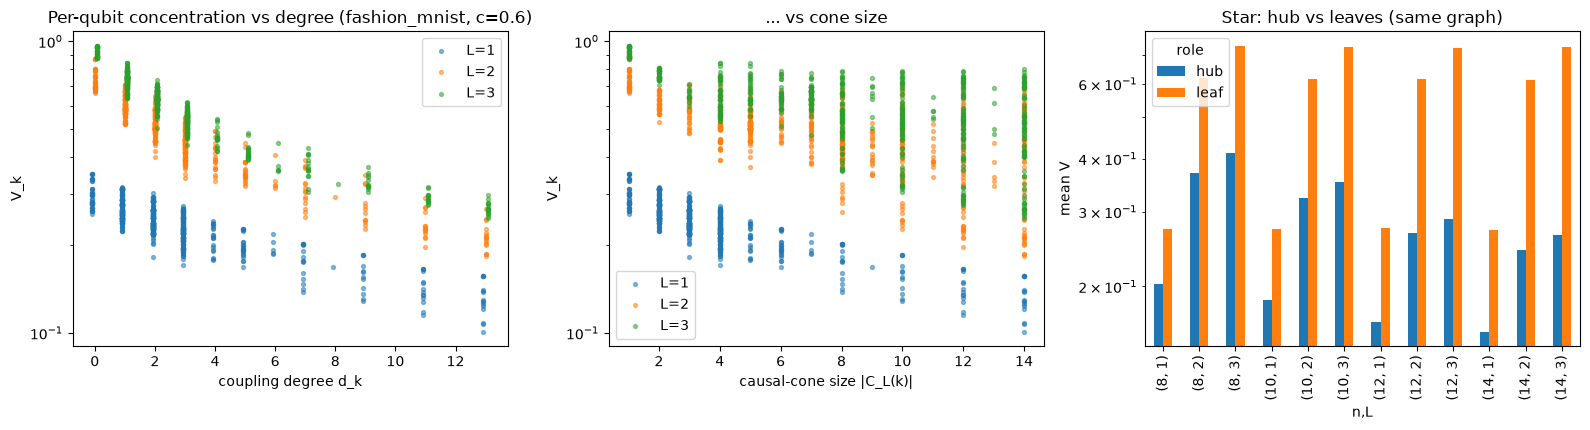

CHECKPOINT 6: verdict and figure saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase1b/run


In [14]:
try:
    import matplotlib.pyplot as plt
    src = "fashion_mnist" if "fashion_mnist" in INPUTS else "gaussian"; c_mid = sorted(BANDWIDTHS)[len(BANDWIDTHS) // 2]
    g = RQ[(RQ.inputs == src) & (RQ.c == c_mid)]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for L, gl in g.groupby("L"):
        ax[0].scatter(gl.degree + 0.08 * (L - 2), gl.V, s=8, alpha=0.5, label=f"L={L}")
        ax[1].scatter(gl.cone, gl.V, s=8, alpha=0.5, label=f"L={L}")
    for a_, xl in zip(ax[:2], ["coupling degree d_k", "causal-cone size |C_L(k)|"]):
        a_.set_yscale("log"); a_.set_xlabel(xl); a_.set_ylabel("V_k"); a_.legend()
    ax[0].set_title(f"Per-qubit concentration vs degree ({src}, c={c_mid})"); ax[1].set_title("... vs cone size")
    s = g[g.graph == "star"]
    if len(s):
        s = s.assign(role=np.where(s.degree > 1, "hub", "leaf")).groupby(["n", "L", "role"]).V.mean().unstack()
        s.plot(kind="bar", ax=ax[2]); ax[2].set_yscale("log"); ax[2].set_title("Star: hub vs leaves (same graph)"); ax[2].set_ylabel("mean V")
    plt.tight_layout(); plt.savefig(RES / "phase1b_figure.png", dpi=160); plt.show()
except ImportError:
    print("matplotlib not installed: figure skipped")
print("CHECKPOINT 6: verdict and figure saved ->", RES)

## What to send back
Zip `pqk-nids/results/phase1b/run/` and send it with this executed notebook and the two files in `pqk-nids/phase1b_freeze/`.